<a href="https://colab.research.google.com/github/gangambikaavanti/ai_lab_programs/blob/main/wee8_1BM24CS101.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Forward Chaining Knowledge Base Input ---
Enter facts exactly as they appear in the slides.
Type 'done' when you are finished entering facts.

Enter fact:  American(Robert)
Enter fact: Enemy(A, America)
Enter fact:  Owns(A, T1)
Enter fact: Missile(T1)
Enter fact: Done

--- Starting Forward Chaining Deduction ---
-> Derived: Weapon(T1) via Missile(T1) => Weapon(T1)
-> Derived: Sells(Robert, T1, A) via Missile(T1) ∧ Owns(A, T1)
-> Derived: Hostile(A) via Enemy(A, America) => Hostile(A)
-> Derived: Criminal(Robert) via American(Robert) ∧ Weapon(T1) ∧ Sells(Robert, T1, A) ∧ Hostile(A)

[SUCCESS] Goal Criminal(Robert) has been successfully proven!

Generating visual proof graph window...


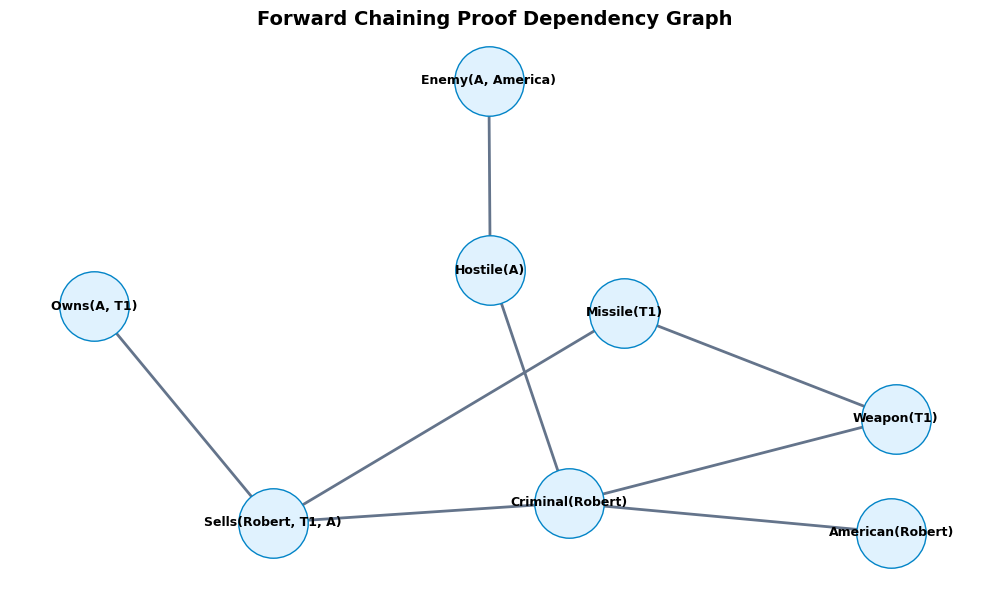

In [2]:
import networkx as nx
import matplotlib.pyplot as plt

class InteractiveForwardChainingKB:
    def __init__(self, initial_facts):
        # Store facts as normalized uppercase tuples
        self.facts = set(initial_facts)

        # Structure to save edges for drawing the dependency graph
        # Format: (parent_node, child_node)
        self.graph_edges = []

        self.rules = [
            self.rule_missile_is_weapon,
            self.rule_missile_sold_by_robert,
            self.rule_enemy_is_hostile,
            self.rule_criminal_definition
        ]

    def format_node(self, fact_tuple):
        """Converts ('AMERICAN', 'ROBERT') back to readable 'American(Robert)' string."""
        if len(fact_tuple) == 1:
            return f"{fact_tuple[0].capitalize()}()"
        return f"{fact_tuple[0].capitalize()}({', '.join([arg.capitalize() for arg in fact_tuple[1:]])})"

    def rule_missile_is_weapon(self):
        new_facts = set()
        for fact in list(self.facts):
            if fact[0] == "MISSILE":
                x = fact[1]
                new_fact = ("WEAPON", x)
                if new_fact not in self.facts:
                    print(f"-> Derived: Weapon({x.capitalize()}) via Missile({x.capitalize()}) => Weapon({x.capitalize()})")
                    new_facts.add(new_fact)
                    # Add dependency edge
                    self.graph_edges.append((self.format_node(fact), self.format_node(new_fact)))
        return new_facts

    def rule_missile_sold_by_robert(self):
        new_facts = set()
        missiles = {f for f in self.facts if f[0] == "MISSILE"}
        owned_by_A = {f for f in self.facts if f[0] == "OWNS" and f[1] == "A"}

        for m_fact in missiles:
            x = m_fact[1]
            for o_fact in owned_by_A:
                if o_fact[2] == x:
                    new_fact = ("SELLS", "ROBERT", x, "A")
                    if new_fact not in self.facts:
                        print(f"-> Derived: Sells(Robert, {x.capitalize()}, A) via Missile({x.capitalize()}) ∧ Owns(A, {x.capitalize()})")
                        new_facts.add(new_fact)
                        # Add tracking edges from both premises
                        self.graph_edges.append((self.format_node(m_fact), self.format_node(new_fact)))
                        self.graph_edges.append((self.format_node(o_fact), self.format_node(new_fact)))
        return new_facts

    def rule_enemy_is_hostile(self):
        new_facts = set()
        for fact in list(self.facts):
            if fact[0] == "ENEMY" and fact[1] == "A" and fact[2] == "AMERICA":
                new_fact = ("HOSTILE", "A")
                if new_fact not in self.facts:
                    print(f"-> Derived: Hostile(A) via Enemy(A, America) => Hostile(A)")
                    new_facts.add(new_fact)
                    self.graph_edges.append((self.format_node(fact), self.format_node(new_fact)))
        return new_facts

    def rule_criminal_definition(self):
        new_facts = set()
        americans = {f for f in self.facts if f[0] == "AMERICAN"}
        weapons = {f for f in self.facts if f[0] == "WEAPON"}
        hostiles = {f for f in self.facts if f[0] == "HOSTILE"}
        sells_records = {f for f in self.facts if f[0] == "SELLS"}

        for am_fact in list(americans):
            p = am_fact[1]
            for wp_fact in list(weapons):
                q = wp_fact[1]
                for hs_fact in list(hostiles):
                    r = hs_fact[1]
                    for sl_fact in list(sells_records):
                        if sl_fact[1] == p and sl_fact[2] == q and sl_fact[3] == r:
                            new_fact = ("CRIMINAL", p)
                            if new_fact not in self.facts:
                                print(f"-> Derived: Criminal({p.capitalize()}) via American({p.capitalize()}) ∧ Weapon({q.capitalize()}) ∧ Sells({p.capitalize()}, {q.capitalize()}, {r.capitalize()}) ∧ Hostile({r.capitalize()})")
                                new_facts.add(new_fact)
                                # Link all 4 conditions to final conclusion
                                self.graph_edges.append((self.format_node(am_fact), self.format_node(new_fact)))
                                self.graph_edges.append((self.format_node(wp_fact), self.format_node(new_fact)))
                                self.graph_edges.append((self.format_node(sl_fact), self.format_node(new_fact)))
                                self.graph_edges.append((self.format_node(hs_fact), self.format_node(new_fact)))
        return new_facts

    def prove(self, goal):
        print("\n--- Starting Forward Chaining Deduction ---")
        while True:
            new_facts_in_iteration = set()
            for rule in self.rules:
                derived = rule()
                new_facts_in_iteration.update(derived)

            if not new_facts_in_iteration:
                break

            self.facts.update(new_facts_in_iteration)

            if goal in self.facts:
                print(f"\n[SUCCESS] Goal {self.format_node(goal)} has been successfully proven!")
                self.draw_proof_graph()
                return True

        print(f"\n[FAILURE] Could not prove the goal.")
        return False

    def draw_proof_graph(self):
        """Builds and opens a matplotlib window mapping out the inference chain graph."""
        print("\nGenerating visual proof graph window...")
        G = nx.DiGraph()
        G.add_edges_from(self.graph_edges)

        plt.figure(figsize=(10, 6))
        plt.title("Forward Chaining Proof Dependency Graph", fontsize=14, fontweight='bold')

        # Use spring layout for clear hierarchy separation
        pos = nx.spring_layout(G, seed=42)

        # Customize node rendering
        nx.draw_networkx_nodes(G, pos, node_size=2500, node_color="#e0f2fe", edgecolors="#0284c7")
        nx.draw_networkx_edges(G, pos, arrowstyle="->", arrowsize=20, edge_color="#64748b", width=2)
        nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold", font_family="sans-serif")

        plt.axis('off')
        plt.tight_layout()
        plt.show()

# Interactive Terminal Prompt
if __name__ == "__main__":
    print("--- Forward Chaining Knowledge Base Input ---")
    print("Enter facts exactly as they appear in the slides.")
    print("Type 'done' when you are finished entering facts.\n")

    input_facts = []
    while True:
        user_input = input("Enter fact: ").strip()
        if user_input.lower() == 'done':
            break

        try:
            predicate, args_str = user_input.split('(', 1)
            args_str = args_str.rstrip(')')
            args = [arg.strip().upper() for arg in args_str.split(',')]

            fact_tuple = tuple([predicate.strip().upper()] + args)
            input_facts.append(fact_tuple)
        except Exception:
            print("❌ Invalid format. Use: Predicate(arg1, arg2)")

    if input_facts:
        kb = InteractiveForwardChainingKB(input_facts)
        target_goal = ("CRIMINAL", "ROBERT")
        kb.prove(target_goal)
    else:
        print("No facts entered. Exiting.")
